In [1]:
!pip install pandas numpy matplotlib pydantic -q


[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
import numpy as np
import json
import re
import hashlib
import matplotlib.pyplot as plt

from pathlib import Path
from pydantic import BaseModel, Field, ConfigDict

In [3]:
base_path = Path("metricmind_week4")

reasoning_path = base_path / "reasoning"
visualization_path = base_path / "visualizations"
output_path = base_path / "outputs"

reasoning_path.mkdir(parents=True, exist_ok=True)
visualization_path.mkdir(parents=True, exist_ok=True)
output_path.mkdir(parents=True, exist_ok=True)

print("Week 4 project folders created successfully.")
print("Base folder:", base_path)
print("Reasoning:", reasoning_path)
print("Visualizations:", visualization_path)
print("Outputs:", output_path)

Week 4 project folders created successfully.
Base folder: metricmind_week4
Reasoning: metricmind_week4\reasoning
Visualizations: metricmind_week4\visualizations
Outputs: metricmind_week4\outputs


In [4]:
sales_data = pd.DataFrame({
    "month": [
        "2026-01",
        "2026-02",
        "2026-03",
        "2026-04",
        "2026-05",
        "2026-06",
        "2026-07",
        "2026-08",
        "2026-09"
    ],

    "revenue": [
        100000,
        105000,
        110000,
        115000,
        120000,
        118000,
        117000,
        116000,
        115000
    ],

    "shipping_cost": [
        10000,
        10500,
        11000,
        11500,
        12000,
        15000,
        19000,
        22000,
        25000
    ],

    "material_cost": [
        40000,
        42000,
        44000,
        46000,
        48000,
        50000,
        52000,
        54000,
        56000
    ]
})

sales_data["total_cost"] = (
    sales_data["shipping_cost"]
    + sales_data["material_cost"]
)

sales_data["profit"] = (
    sales_data["revenue"]
    - sales_data["total_cost"]
)

sales_data["margin"] = (
    sales_data["profit"]
    / sales_data["revenue"]
) * 100

print("Business dataset created successfully.")

display(sales_data)

Business dataset created successfully.


,month,revenue,shipping_cost,material_cost,total_cost,profit,margin
0,2026-01,100000,10000,40000,50000,50000,50.000000
1,2026-02,105000,10500,42000,52500,52500,50.000000
2,2026-03,110000,11000,44000,55000,55000,50.000000
3,2026-04,115000,11500,46000,57500,57500,50.000000
4,2026-05,120000,12000,48000,60000,60000,50.000000
5,2026-06,118000,15000,50000,65000,53000,44.915254
6,2026-07,117000,19000,52000,71000,46000,39.316239
7,2026-08,116000,22000,54000,76000,40000,34.482759
8,2026-09,115000,25000,56000,81000,34000,29.565217


In [5]:
print("Monthly margins:")

display(
    sales_data[
        ["month", "revenue", "total_cost", "profit", "margin"]
    ]
)

Monthly margins:


,month,revenue,total_cost,profit,margin
0,2026-01,100000,50000,50000,50.000000
1,2026-02,105000,52500,52500,50.000000
2,2026-03,110000,55000,55000,50.000000
3,2026-04,115000,57500,57500,50.000000
4,2026-05,120000,60000,60000,50.000000
5,2026-06,118000,65000,53000,44.915254
6,2026-07,117000,71000,46000,39.316239
7,2026-08,116000,76000,40000,34.482759
8,2026-09,115000,81000,34000,29.565217


In [6]:
sales_data["margin_change"] = (
    sales_data["margin"].diff()
)

print("Margin change calculated.")

display(
    sales_data[
        ["month", "margin", "margin_change"]
    ]
)

Margin change calculated.


,month,margin,margin_change
0,2026-01,50.000000,NaN
1,2026-02,50.000000,0.000000
2,2026-03,50.000000,0.000000
3,2026-04,50.000000,0.000000
4,2026-05,50.000000,0.000000
5,2026-06,44.915254,-5.084746
6,2026-07,39.316239,-5.599015
7,2026-08,34.482759,-4.833481
8,2026-09,29.565217,-4.917541


In [7]:
MARGIN_DROP_THRESHOLD = -1.0

print(
    "Margin drop threshold:",
    MARGIN_DROP_THRESHOLD,
    "percentage points"
)

Margin drop threshold: -1.0 percentage points


In [8]:
def detect_margin_drop(data):

    latest_row = data.iloc[-1]

    previous_row = data.iloc[-2]

    latest_margin = latest_row["margin"]

    previous_margin = previous_row["margin"]

    margin_change = latest_margin - previous_margin

    return {
        "margin_dropped": margin_change < MARGIN_DROP_THRESHOLD,
        "latest_margin": latest_margin,
        "previous_margin": previous_margin,
        "margin_change": margin_change
    }


margin_status = detect_margin_drop(
    sales_data
)

print(json.dumps(
    margin_status,
    indent=2,
    default=float
))

{
  "margin_dropped": 1.0,
  "latest_margin": 29.565217391304348,
  "previous_margin": 34.48275862068966,
  "margin_change": -4.917541229385311
}


In [9]:
primary_query = {
    "query_type": "margin_analysis",

    "measures": [
        "sales.revenue",
        "sales.cost"
    ],

    "dimensions": [
        "sales.month"
    ]
}

print(
    json.dumps(
        primary_query,
        indent=2
    )
)

{
  "query_type": "margin_analysis",
  "measures": [
    "sales.revenue",
    "sales.cost"
  ],
  "dimensions": [
    "sales.month"
  ]
}


In [10]:
secondary_queries = {
    "shipping_cost_analysis": {
        "query_type": "root_cause_analysis",

        "measure": "sales.shipping_cost",

        "dimension": "sales.month"
    },

    "material_cost_analysis": {
        "query_type": "root_cause_analysis",

        "measure": "sales.material_cost",

        "dimension": "sales.month"
    }
}

print(
    json.dumps(
        secondary_queries,
        indent=2
    )
)

{
  "shipping_cost_analysis": {
    "query_type": "root_cause_analysis",
    "measure": "sales.shipping_cost",
    "dimension": "sales.month"
  },
  "material_cost_analysis": {
    "query_type": "root_cause_analysis",
    "measure": "sales.material_cost",
    "dimension": "sales.month"
  }
}


In [11]:
def multi_step_reasoning(data):

    margin_analysis = detect_margin_drop(data)

    reasoning_steps = []

    reasoning_steps.append({
        "step": 1,
        "action": "Check margin",
        "result": margin_analysis
    })

    if margin_analysis["margin_dropped"]:

        reasoning_steps.append({
            "step": 2,
            "action": "Investigate shipping costs",
            "query": secondary_queries[
                "shipping_cost_analysis"
            ]
        })

        reasoning_steps.append({
            "step": 3,
            "action": "Investigate material costs",
            "query": secondary_queries[
                "material_cost_analysis"
            ]
        })

        reasoning_steps.append({
            "step": 4,
            "action": "Compare cost drivers",
            "status": "Triggered"
        })

    else:

        reasoning_steps.append({
            "step": 2,
            "action": "Root-cause analysis",
            "status": "Not required"
        })

    return reasoning_steps


reasoning_result = multi_step_reasoning(
    sales_data
)

print(
    json.dumps(
        reasoning_result,
        indent=2,
        default=float
    )
)

[
  {
    "step": 1,
    "action": "Check margin",
    "result": {
      "margin_dropped": 1.0,
      "latest_margin": 29.565217391304348,
      "previous_margin": 34.48275862068966,
      "margin_change": -4.917541229385311
    }
  },
  {
    "step": 2,
    "action": "Investigate shipping costs",
    "query": {
      "query_type": "root_cause_analysis",
      "measure": "sales.shipping_cost",
      "dimension": "sales.month"
    }
  },
  {
    "step": 3,
    "action": "Investigate material costs",
    "query": {
      "query_type": "root_cause_analysis",
      "measure": "sales.material_cost",
      "dimension": "sales.month"
    }
  },
  {
    "step": 4,
    "action": "Compare cost drivers",
    "status": "Triggered"
  }
]


In [13]:
latest = sales_data.iloc[-1]
previous = sales_data.iloc[-2]

shipping_change = (
    latest["shipping_cost"]
    - previous["shipping_cost"]
)

material_change = (
    latest["material_cost"]
    - previous["material_cost"]
)

root_cause_data = {
    "shipping_cost_change": int(shipping_change),
    "material_cost_change": int(material_change)
}

print("Root-cause cost changes:")

print(
    json.dumps(
        root_cause_data,
        indent=2
    )
)

Root-cause cost changes:
{
  "shipping_cost_change": 3000,
  "material_cost_change": 2000
}


In [14]:
cost_changes = {
    "Shipping Costs": shipping_change,
    "Material Costs": material_change
}

largest_driver = max(
    cost_changes,
    key=cost_changes.get
)

print("Cost changes:")
print(cost_changes)

print("\nLargest cost increase:")
print(largest_driver)

Cost changes:
{'Shipping Costs': np.int64(3000), 'Material Costs': np.int64(2000)}

Largest cost increase:
Shipping Costs


In [18]:
# Cell 14 - Corrected JSON-safe agent reasoning result

def make_json_safe(obj):
    """
    Convert NumPy/Pandas data types into
    standard Python types.
    """

    if isinstance(obj, dict):
        return {
            str(key): make_json_safe(value)
            for key, value in obj.items()
        }

    elif isinstance(obj, list):
        return [
            make_json_safe(value)
            for value in obj
        ]

    elif isinstance(obj, tuple):
        return [
            make_json_safe(value)
            for value in obj
        ]

    elif isinstance(obj, np.generic):
        return obj.item()

    else:
        return obj


agent_reasoning_result = {
    "question": "Why did margins drop?",

    "initial_analysis": {
        "latest_margin": float(
            margin_status["latest_margin"]
        ),

        "previous_margin": float(
            margin_status["previous_margin"]
        ),

        "margin_change": float(
            margin_status["margin_change"]
        ),

        "margin_dropped": bool(
            margin_status["margin_dropped"]
        )
    },

    "reasoning": reasoning_result,

    "root_cause": {
        "shipping_cost_change": int(
            shipping_change
        ),

        "material_cost_change": int(
            material_change
        ),

        "largest_cost_driver": str(
            largest_driver
        )
    }
}

# Convert every nested NumPy/Pandas value
agent_reasoning_result = make_json_safe(
    agent_reasoning_result
)

print(
    json.dumps(
        agent_reasoning_result,
        indent=2
    )
)

{
  "question": "Why did margins drop?",
  "initial_analysis": {
    "latest_margin": 29.565217391304348,
    "previous_margin": 34.48275862068966,
    "margin_change": -4.917541229385311,
    "margin_dropped": true
  },
  "reasoning": [
    {
      "step": 1,
      "action": "Check margin",
      "result": {
        "margin_dropped": true,
        "latest_margin": 29.565217391304348,
        "previous_margin": 34.48275862068966,
        "margin_change": -4.917541229385311
      }
    },
    {
      "step": 2,
      "action": "Investigate shipping costs",
      "query": {
        "query_type": "root_cause_analysis",
        "measure": "sales.shipping_cost",
        "dimension": "sales.month"
      }
    },
    {
      "step": 3,
      "action": "Investigate material costs",
      "query": {
        "query_type": "root_cause_analysis",
        "measure": "sales.material_cost",
        "dimension": "sales.month"
      }
    },
    {
      "step": 4,
      "action": "Compare cost drivers"

In [19]:
json_data = sales_data.to_dict(
    orient="records"
)

json_string = json.dumps(
    json_data,
    indent=2
)

print(json_string)

[
  {
    "month": "2026-01",
    "revenue": 100000,
    "shipping_cost": 10000,
    "material_cost": 40000,
    "total_cost": 50000,
    "profit": 50000,
    "margin": 50.0,
    "margin_change": NaN
  },
  {
    "month": "2026-02",
    "revenue": 105000,
    "shipping_cost": 10500,
    "material_cost": 42000,
    "total_cost": 52500,
    "profit": 52500,
    "margin": 50.0,
    "margin_change": 0.0
  },
  {
    "month": "2026-03",
    "revenue": 110000,
    "shipping_cost": 11000,
    "material_cost": 44000,
    "total_cost": 55000,
    "profit": 55000,
    "margin": 50.0,
    "margin_change": 0.0
  },
  {
    "month": "2026-04",
    "revenue": 115000,
    "shipping_cost": 11500,
    "material_cost": 46000,
    "total_cost": 57500,
    "profit": 57500,
    "margin": 50.0,
    "margin_change": 0.0
  },
  {
    "month": "2026-05",
    "revenue": 120000,
    "shipping_cost": 12000,
    "material_cost": 48000,
    "total_cost": 60000,
    "profit": 60000,
    "margin": 50.0,
    "margin_c

In [20]:
def detect_chart_type(data, x_column):

    if x_column == "month":
        return "line"

    if data[x_column].dtype == "object":
        return "bar"

    return "bar"


print(
    "Visualization detector created."
)

Visualization detector created.


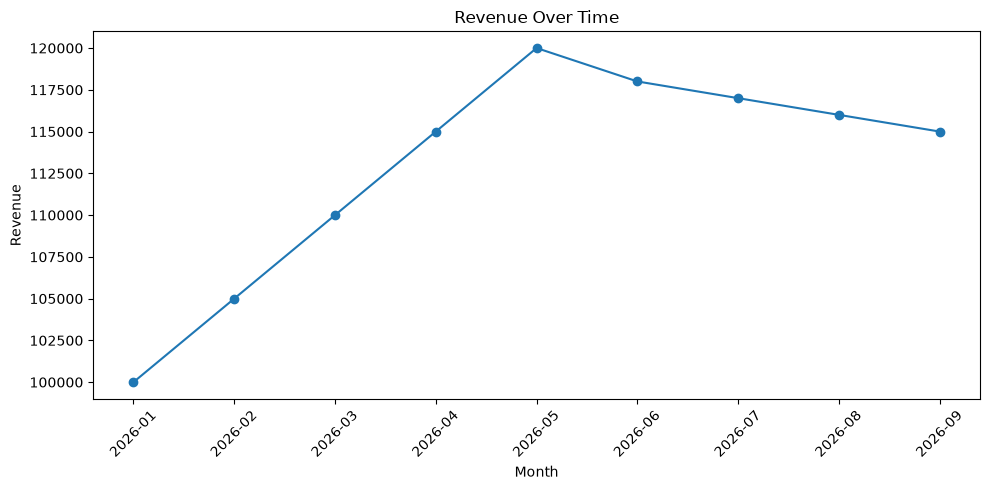

Detected chart type: line


In [21]:
def render_dynamic_chart(
    data,
    x_column,
    y_column
):

    chart_type = detect_chart_type(
        data,
        x_column
    )

    plt.figure(figsize=(10, 5))

    if chart_type == "line":

        plt.plot(
            data[x_column],
            data[y_column],
            marker="o"
        )

        plt.title(
            f"{y_column.replace('_', ' ').title()} Over Time"
        )

        plt.xlabel(
            x_column.replace("_", " ").title()
        )

        plt.ylabel(
            y_column.replace("_", " ").title()
        )

    elif chart_type == "bar":

        plt.bar(
            data[x_column],
            data[y_column]
        )

        plt.title(
            f"{y_column.replace('_', ' ').title()} by Category"
        )

        plt.xlabel(
            x_column.replace("_", " ").title()
        )

        plt.ylabel(
            y_column.replace("_", " ").title()
        )

    plt.xticks(rotation=45)

    plt.tight_layout()

    plt.show()

    return chart_type


chart_type = render_dynamic_chart(
    sales_data,
    "month",
    "revenue"
)

print(
    "Detected chart type:",
    chart_type
)

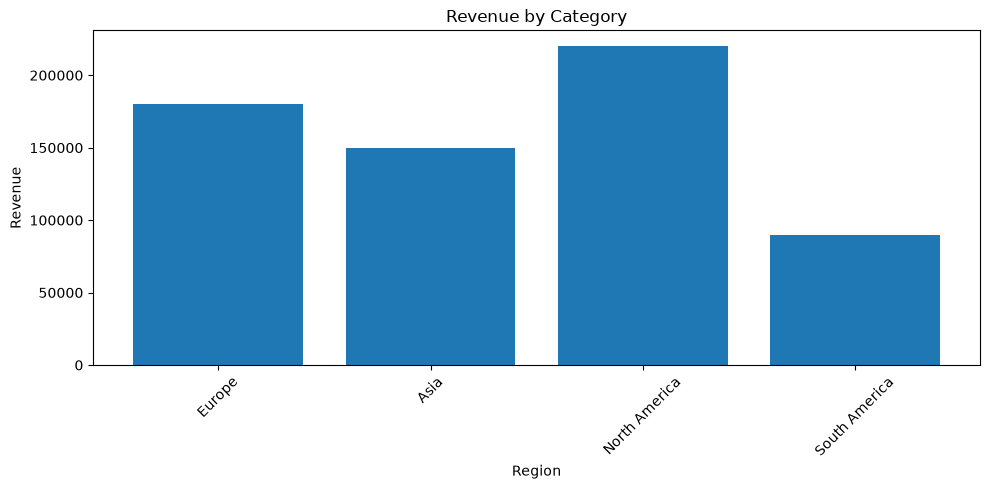

Detected chart type: bar


In [22]:
regional_data = pd.DataFrame({
    "region": [
        "Europe",
        "Asia",
        "North America",
        "South America"
    ],

    "revenue": [
        180000,
        150000,
        220000,
        90000
    ]
})

chart_type = render_dynamic_chart(
    regional_data,
    "region",
    "revenue"
)

print(
    "Detected chart type:",
    chart_type
)

JSON successfully parsed.
Detected chart type: line


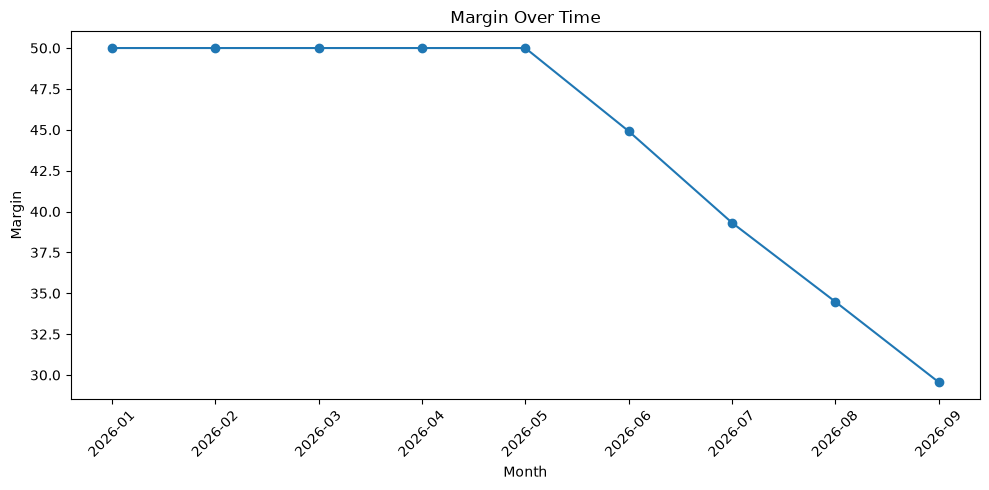

{
  "chart_type": "line",
  "x_column": "month",
  "y_column": "margin"
}


In [23]:
def json_to_dynamic_chart(
    json_string,
    x_column,
    y_column
):

    data = pd.DataFrame(
        json.loads(json_string)
    )

    chart_type = detect_chart_type(
        data,
        x_column
    )

    print("JSON successfully parsed.")
    print("Detected chart type:", chart_type)

    render_dynamic_chart(
        data,
        x_column,
        y_column
    )

    return {
        "chart_type": chart_type,
        "x_column": x_column,
        "y_column": y_column
    }


visualization_result = json_to_dynamic_chart(
    json_string,
    "month",
    "margin"
)

print(
    json.dumps(
        visualization_result,
        indent=2
    )
)

In [24]:
chart_spec = {
    "chart_type": visualization_result[
        "chart_type"
    ],

    "x_axis": visualization_result[
        "x_column"
    ],

    "y_axis": visualization_result[
        "y_column"
    ],

    "data_source": "MetricMind JSON response"
}

print(
    json.dumps(
        chart_spec,
        indent=2
    )
)

{
  "chart_type": "line",
  "x_axis": "month",
  "y_axis": "margin",
  "data_source": "MetricMind JSON response"
}


In [25]:
def metricmind_week4_agent(
    question,
    data
):

    result = {
        "question": question,
        "status": "success"
    }

    # Step 1: Analyze margin
    margin_analysis = detect_margin_drop(
        data
    )

    result["margin_analysis"] = margin_analysis

    # Step 2: Trigger secondary investigation
    if margin_analysis["margin_dropped"]:

        result["secondary_analysis"] = {
            "shipping_cost": {
                "previous": float(
                    data.iloc[-2]["shipping_cost"]
                ),

                "latest": float(
                    data.iloc[-1]["shipping_cost"]
                )
            },

            "material_cost": {
                "previous": float(
                    data.iloc[-2]["material_cost"]
                ),

                "latest": float(
                    data.iloc[-1]["material_cost"]
                )
            }
        }

        result["root_cause"] = largest_driver

    else:

        result["secondary_analysis"] = None
        result["root_cause"] = None

    # Step 3: Prepare visualization
    result["visualization"] = {
        "chart_type": "line",
        "x_axis": "month",
        "y_axis": "margin"
    }

    return result


final_agent_result = metricmind_week4_agent(
    "Why did margins drop?",
    sales_data
)

print(
    json.dumps(
        final_agent_result,
        indent=2,
        default=float
    )
)

{
  "question": "Why did margins drop?",
  "status": "success",
  "margin_analysis": {
    "margin_dropped": 1.0,
    "latest_margin": 29.565217391304348,
    "previous_margin": 34.48275862068966,
    "margin_change": -4.917541229385311
  },
  "secondary_analysis": {
    "shipping_cost": {
      "previous": 22000.0,
      "latest": 25000.0
    },
    "material_cost": {
      "previous": 54000.0,
      "latest": 56000.0
    }
  },
  "root_cause": "Shipping Costs",
  "visualization": {
    "chart_type": "line",
    "x_axis": "month",
    "y_axis": "margin"
  }
}


In [26]:
print("=" * 70)
print("METRICMIND WEEK 4 VALIDATION")
print("=" * 70)

# Multi-step reasoning
if (
    final_agent_result["secondary_analysis"]
    is not None
):
    reasoning_status = "PASS"
else:
    reasoning_status = "FAIL"

print(
    "\n1. MULTI-STEP REASONING:",
    reasoning_status
)

# Root cause
if final_agent_result["root_cause"] is not None:
    root_cause_status = "PASS"
else:
    root_cause_status = "FAIL"

print(
    "2. ROOT-CAUSE ANALYSIS:",
    root_cause_status
)

# Visualization
if (
    final_agent_result["visualization"][
        "chart_type"
    ] == "line"
):
    visualization_status = "PASS"
else:
    visualization_status = "FAIL"

print(
    "3. DYNAMIC VISUALIZATION:",
    visualization_status
)

overall_status = (
    reasoning_status == "PASS"
    and root_cause_status == "PASS"
    and visualization_status == "PASS"
)

print(
    "\nOVERALL STATUS:",
    "PASS" if overall_status else "FAIL"
)

METRICMIND WEEK 4 VALIDATION

1. MULTI-STEP REASONING: PASS
2. ROOT-CAUSE ANALYSIS: PASS
3. DYNAMIC VISUALIZATION: PASS

OVERALL STATUS: PASS


In [27]:
week4_report = {
    "project": "MetricMind",

    "week": 4,

    "features": {
        "multi_step_reasoning": True,
        "automatic_root_cause_analysis": True,
        "shipping_cost_analysis": True,
        "material_cost_analysis": True,
        "dynamic_visualization": True,
        "json_parsing": True
    },

    "margin_analysis": {
        "latest_margin": float(
            margin_status["latest_margin"]
        ),

        "previous_margin": float(
            margin_status["previous_margin"]
        ),

        "margin_change": float(
            margin_status["margin_change"]
        )
    },

    "root_cause": {
        "shipping_cost_change": float(
            shipping_change
        ),

        "material_cost_change": float(
            material_change
        ),

        "largest_driver": largest_driver
    },

    "visualization": chart_spec,

    "overall_status": (
        "PASS"
        if overall_status
        else "FAIL"
    )
}

report_file = (
    output_path /
    "week4_reasoning_visualization_report.json"
)

with open(
    report_file,
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        week4_report,
        file,
        indent=2
    )

print("=" * 70)
print("METRICMIND WEEK 4 COMPLETED")
print("=" * 70)

print(
    "\nMulti-Step Reasoning:",
    reasoning_status
)

print(
    "Root-Cause Analysis:",
    root_cause_status
)

print(
    "Dynamic Visualization:",
    visualization_status
)

print(
    "Overall Status:",
    "PASS" if overall_status else "FAIL"
)

print("\nLargest cost driver:")
print(largest_driver)

print("\nReport saved to:")
print(report_file)

METRICMIND WEEK 4 COMPLETED

Multi-Step Reasoning: PASS
Root-Cause Analysis: PASS
Dynamic Visualization: PASS
Overall Status: PASS

Largest cost driver:
Shipping Costs

Report saved to:
metricmind_week4\outputs\week4_reasoning_visualization_report.json
